# Chapter 6: Simulation-PDE

> 📽️ [Slides for this chapter](https://leibniz-iwt.github.io/comp_eng/slides/06_simulation-pde.slides.html) · 🐍 Helper code: [`compeng/ch06_simulation_pde.py`](https://github.com/Leibniz-IWT/comp_eng/blob/main/notebooks/compeng/ch06_simulation_pde.py)

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.linalg import solve

from compeng.plotting import setup

setup()

In this chapter we will explore numerical simulation techniques for solving partial differential equations (PDEs) commonly encountered in engineering applications. Before we get started on numerical methods, it is important, as always, to build a common nomenclature through a classification scheme so that we can better understand which numerical methods are best suited for solving different types of PDEs.

## 1. Classification of partial differential equations

Partial differential equations (PDEs) are classified based on their mathematical structure, which influences the behavior of solutions and the appropriate numerical methods for solving them. Following the approach in Farlow's Partial Differential Equations for Scientists and Engineers (1993), second-order linear PDEs in two variables can be classified analogously to conic sections in algebra. Consider the general form:

$$ a \frac{\partial^2 y}{\partial x^2} + b \frac{\partial^2 y}{\partial x \partial t} + c \frac{\partial^2 y}{\partial t^2} + d \frac{\partial y}{\partial x} + e \frac{\partial y}{\partial t} + f y = g, $$

where $a, b, c, d, e, f,$ and $g$ are coefficients (possibly functions of $x$ and $t$), and the classification is determined by the discriminant of the quadratic form in the second derivatives: $b^2 - 4ac$.

- If $b^2 - 4ac < 0$: the PDE is elliptic. Elliptic PDEs typically describe steady-state or equilibrium phenomena, with smooth solutions. Example: Laplace's equation $\nabla^2 y = 0$ (steady heat conduction or electrostatic potential in spacecraft design).
- If $b^2 - 4ac = 0$: the PDE is parabolic. Parabolic PDEs model diffusion processes, where information spreads over time. Example: The heat equation $\frac{\partial y}{\partial t} = \alpha \nabla^2 y$ (transient thermal management in satellites).
- If $b^2 - 4ac > 0$: the PDE is hyperbolic. Hyperbolic PDEs govern wave-like propagation, with solutions that can exhibit discontinuities or shocks. Example: The wave equation $\frac{\partial^2 y}{\partial t^2} = c^2 \nabla^2 y$ (acoustic waves in rocket propulsion systems).

This classification extends to higher dimensions and non-constant coefficients by evaluating the discriminant locally, though the behavior may vary spatially. Several numerical methods are available for solving PDEs, each suited to different types and geometries. Here, we briefly overview finite difference methods (FDM), finite element methods (FEM), and finite volume methods (FVM).

### 1.1 Common Numerical Methods for solving PDEs
#### Finite Difference Methods (FDM):
FDM approximates derivatives using Taylor series expansions on a structured grid (e.g., central differences for second derivatives).
- Advantages: Simple to implement, computationally efficient for regular domains, easy to understand for beginners.
- Disadvantages: Less flexible for complex geometries or irregular boundaries; can introduce numerical artifacts like dispersion in hyperbolic problems.
- Applications: Heat conduction in uniform materials (parabolic PDEs) or wave propagation in simple domains (hyperbolic PDEs), such as thermal analysis of satellite panels.

#### Finite Element Methods (FEM):
FEM divides the domain into unstructured elements (e.g., triangles or tetrahedra) and approximates solutions using basis functions within each element, solving via weak formulations.
- Advantages: Highly flexible for complex geometries and boundaries; naturally handles variable material properties; good for elliptic and structural problems.
- Disadvantages: More computationally intensive (requires matrix assembly and solving large sparse systems); steeper learning curve.
- Applications: Structural mechanics in spacecraft (e.g., elliptic PDEs for stress analysis) or fluid-structure interactions.

#### Finite Volume Methods (FVM):
FVM integrates the PDE over control volumes, enforcing conservation laws (e.g., flux balances at cell interfaces).
- Advantages: Inherently conservative (preserves mass, energy); suitable for unstructured grids and hyperbolic problems with shocks.
- Disadvantages: Can be more complex to implement for higher-order accuracy; less straightforward for non-conservative forms.
- Applications: Fluid dynamics in aerospace (e.g., Navier-Stokes equations for propulsion flows) or heat transfer in porous media.

The choice depends on the PDE type: FDM for quick prototypes on grids, FEM for solids and complex shapes, FVM for fluids and conservation-critical problems.

#### Non-Linear PDEs and Solution Methods
Many engineering PDEs are non-linear (e.g., due to variable coefficients like temperature-dependent conductivity or advective terms in fluids). Unlike linear PDEs, they lack superposition and often require iterative techniques:

##### Iterative Methods:
Linearize the PDE (e.g., via Newton's method) and solve successively. For example, in non-linear heat equations, iterate on an approximate Jacobian until convergence. Picard iteration (fixed-point) is simpler but slower.

##### Perturbation Methods:
For weakly non-linear problems, expand solutions as a series around a small parameter (e.g., $\epsilon$) and solve order-by-order. Useful for asymptotic approximations in boundary layers or small-amplitude waves.

These can be combined with the above discretization methods (e.g., non-linear FVM solvers).

### 1.2 Challenges in solving PDEs
Solving PDEs in engineering poses several challenges:

- Stability: Explicit schemes may require small time steps (e.g., CFL-like conditions) to avoid oscillations or divergence; implicit methods improve stability but increase computational cost.
- Convergence: Solutions must approach the true PDE as grid/time steps refine; requires verification via Richardson extrapolation or grid studies.
- Accuracy: Numerical diffusion (smearing sharp features) or dispersion (phase errors in waves) can distort results; higher-order schemes help but amplify instability.
- Other issues include handling discontinuities (shocks in hyperbolic PDEs), high-dimensionality (curse of dimensionality), and multi-scale phenomena (e.g., turbulence in space propulsion), often requiring adaptive meshes or parallel computing.

In space engineering, these challenges are critical for reliable simulations, such as re-entry heat shields (parabolic/elliptic) or orbital dynamics (hyperbolic). Always validate against analytical solutions or experiments where possible.

## 2. General principles of PDE discretization

### 2.1 Spatio-temporal integrators and the method of lines (MOL)
In general, the structure of numerical solutions of PDEs can be found very similar to the **integrators** we used for solving ODEs. As a quick reminder, the simplest time discretization method (the Euler method) for solving the ODE $\frac{d\mathbf{y}}{dt}(t) = \mathbf{f}(\mathbf{y}(t), t, \mathbf{p})$ is given by the finite difference approximation:

$$\frac{d\mathbf{y}}{dt}(t) \approx \frac{\mathbf{y}_{n+1} -  \mathbf{y}_n}{ \Delta t}  = \mathbf{f}(\mathbf{y}(t), t, \mathbf{p}),$$

so,

$$\mathbf{y}^{n+1} \approx \mathbf{y}^n + \Delta t \cdot \mathbf{f}(\mathbf{y}(t), t, \mathbf{p}),$$

>NOTE: We will use superscripts to denote discrete time steps (before it was subscript) and subscripts to denote spatial elements throughout this chapter.

Which can be solved with a code that looks something like this:

```python
for t in timespan:  # Loop over the time span of the simulation
    y = y + dydt(t, y) * dt  # Step forward in time for 1 time step
```

Now the difference is that a PDE typically contains not only time derivatives but also spatial derivatives. To solve PDEs numerically, we need to discretize both time and space. This can be done using various numerical methods, such as the finite difference method (FDM), finite element method (FEM), and finite volume method (FVM) and different methods work better for stability and solving different types of PDE. The simplest method for our understanding, however, is yet again the finite difference method, which approximates the spatial derivatives using finite differences. For a simple PDE like $\frac{\partial y}{\partial t} = \alpha \frac{\partial y}{\partial x}$ we can discretize the right hand side using a finite difference approximation:

$$\frac{\partial y}{\partial x} \approx \frac{y^n_{i+1} - y^n_{i}}{\Delta x},$$

where $y^n_i$ is the value of $y$ at the spatial grid point $i$ and $\Delta x$ is the spatial step size. Unlike before where we built an integrator by rearranging the equation, we will now take the method of lines (MOL) approach and simply substitute the spatial discretization into the PDE to obtain a system of ODEs that can be solved using standard ODE integrators. To understand why this is possible note that the spatial discretization above contains only the state of dynamic variables $y$ at the current time (denoted by the superscript $n$), so we can always build a spatial operator like (1D):

```python

def dydx(y):
    dydx = np.zeros_like(y)
    for i in range(N_x_i):
        dydx[i] = (y[i + 1] - y[i]) / dx
    return dydx
```

where `N_x_i` is the number of spatial discretizations (more detail on this later). Then we can substitute this vector into the PDE to obtain a system of ODEs, which in code looks like this:

```python
def dydt(t, y):
    return alpha * dydx(y)

for t in timespan:  # Loop over the time span of the simulation
    y = y + dydt(t, y) * dt  # Step forward in time for 1 time step
```

It is important to point out that, like our ODE integrators, the choice of spatial discretization method can have a significant impact on the stability and accuracy of the numerical solution. For example, implicit methods also exist in which case we adapt our integrator exactly like we did for ODEs. The choice of spatial discretization method and time integration method should be made based on the specific PDE being solved and the desired accuracy and stability of the solution. This is a matter of experience which means that you can often learn the best methods for application by reading literature papers in your field of study. Failing available literature, a good starting point is to first classify your PDE according to the scheme above and then choose a method that is known to work well for that class of PDEs.

### 2.2 The initial, boundary value problem (IBVP)

The spatial discretization above solves the PDE in the _interior_ of the domain $\Omega$, but to obtain a unique solution we also need to specify initial conditions (ICs) and boundary conditions (BCs) (the boundary of the domain is typically denoted by $\partial \Omega$). The domain is best understood as the _fixed_ spatial domain $\mathcal{X} \in \Omega$ and the PDE produces a dynamic state $\mathcal{Y}$ that can be mapped to each point in $\mathcal{X}$ through the PDE. The ICs specify the state of the system at the initial time $t = 0$ while the boundary conditions specify the behavior of the solution at the boundaries of the spatial domain which is needed for the system degrees of freedom to be zero and therefore solvable.

#### 2.2.1 IBVP definition and implementation
>
> **Definition:** of the **Initial Boundary Value Problem (IBVP)**: An IBVP consists of a PDE governing the evolution of a dynamic variable $  y(\mathbf{x}, t)  $ over a spatial domain $  \Omega \subset \mathbb{R}^d  $ (where $  d  $ is the dimension, e.g., 1, 2, or 3) and time $  t \geq 0  $, supplemented by initial conditions (ICs) specifying $  \mathbf{y}(\mathbf{x}, 0)  $ for all $  \mathbf{x} \in \Omega  $, and boundary conditions (BCs) on the boundary $  \partial \Omega  $. In vector form for discretized systems, the IBVP becomes a system of ODEs $  \frac{d\mathbf{y}}{dt} = \mathbf{f}(\mathbf{y}, t, \mathbf{p})  $ with $  \mathbf{y}(0) = \mathbf{y}_0  $ and BCs incorporated into $  \mathbf{f}  $ or as constraints.

In our generic code framework for dynamic integrators we can insert the ICs and BCs as follows:

```python
# ICs defined first: Initialize the state variable y with initial conditions

# BCs defined next:
# Define the boundary conditions (which are fixed functions in the simulation even if they depend on time)
def BC_lower(t, y):  # lower or left boundary
    return # some function of y and time

def BC_upper(t, y):  # upper or right boundary
    return # some function of y and time

# Remainder of the IBVP solver ties to dynamic looping:
# Define the RHS of the PDE including boundary conditions
def dydt(t, y):
    # Compute the boundary conditions and update y at the boundaries
    y[0] = BC_lower(t, y)  # Example the boundary of the lower end of the domain
    y[-1] = BC_upper(t, y)  # Example the boundary of the upper end of the domain
    # Compute the spatial derivative in the interior and return the RHS of the PDE:
    return alpha * dydx(y)

for t in timespan:  # Loop over the time span of the simulation
    y = y + dydt(t, y) * dt  # Step forward in time for 1 time step
```

#### 2.2.2 Common types of boundary conditions

There are several types of boundary conditions commonly used in PDEs:

> **Definition: Dirichlet Boundary Conditions:** These specify the value of $y$ on the boundary, e.g., $y(\mathbf{x}, t) = g(\mathbf{x}, t)$ for $\mathbf{x} \in \partial \Omega$, where $g$ is a known function (e.g., fixed temperature).

In a code example, for a 1D grid with a lower/left boundary at $i=0$:

``` python
def BC_lower(t, y):
    return g  # Fixed value, e.g., y[0] = 0 for zero temperature (insulated is a Neumann BC, below)
```

> **Definition: Neumann Boundary Conditions:** These specify the normal derivative (flux) on the boundary, e.g., $\frac{\partial y}{\partial n}(\mathbf{x}, t) = h(\mathbf{x}, t)$ for $\mathbf{x} \in \partial \Omega$, where $n$ is the outward normal (e.g., no-flux for insulation).

In a code example, approximate the derivative for a 1D upper/right boundary at $i=N-1$:

``` python
def BC_upper(t, y):
    # from (y[N-1] - y[N-2]) / dx = h  # Solve for y[N-1], or set h = 0 for no-flux (insulated)
    return y[N-2] + h * dx
```

> **Definition: Robin (Mixed) Boundary Conditions:** These combine Dirichlet and Neumann, e.g., $\frac{\partial y}{\partial n}(\mathbf{x}, t) + \beta y(\mathbf{x}, t) = k(\mathbf{x}, t)$ for $\mathbf{x} \in \partial \Omega$, where $\beta$ and $k$ are known (e.g., convective heat transfer).

In code, for a 1D left boundary:

```python
def BC_lower(t, y):
    # from (y[0] - y[1]) / dx + beta * y[0] = k  # dy/dn with the outward normal -x; solve for y[0]
    return (k + (y[1] / dx)) / (beta + (1 / dx))  # Rearranged implicitly
```

Before discussing advanced methods for solving PDEs, we will first demonstrate general principles of discretization in the context of the heat equation using the FDM/FVM discretization (equivalent in 1D). The FVM is a widely used numerical technique for solving PDEs in engineering applications, particularly in fluid dynamics and heat transfer. It is based on the principle of conservation of mass, momentum, and energy within a control volume.

## 3. Parabolic PDEs and diffusion type problems: simulating the heat equation in Python with FDM
Diffusion type problems are common in engineering applications, particularly in heat transfer and fluid dynamics. It is also relatively easy to simulate because smoothing is inherent in the PDE. The prototypical diffusion equation is the transient heat equation, which describes how heat diffuses through a material over time.

### 3.1 The General Heat Equation

The transient heat equation is a PDE which is used to model heat flow and diffusion-type problems common in Space Engineering. If the thermal conductivity is approximately constant, the heat equation can be stated in a general linear form:

$$\frac{\partial y}{ \partial t} = \alpha \nabla^2 y - h \dot{y} + \dot{e}_{gen},$$

* $y$ is the internal energy ($y = \rho c_p T$)
* $\alpha \nabla^2 y$ is the conduction term
  * $\alpha = \frac{\kappa}{\rho c_p }$ is the thermal diffusivity constant where
    * $\kappa$ is thermal conductivity (W/(m·K))
    * $\rho$ is density (kg/m³)
    * $c_{p}$ is specific heat capacity (J/(kg·K))
  * $\nabla^2$ (sometimes written as $\Delta = \nabla \cdot \nabla$) is the Laplacian operator
* $h \dot{y}$ is the convection term
  * $h$ is the convection coefficient
  * $\dot{y}$ is the heat flux density ($\dot{Q} = \dot{y} A_s$),
* $\dot{e}_{gen}$ is the heat generated ($\dot{Q} = \dot{e}_{gen} V$)

Note that if any of the constant parameters vary with temperature, the equation will become non-linear. For example, if the thermal conductivity is a strong function of temperature, the equation becomes:

$$\frac{\partial y}{ \partial t} = \frac{1}{\rho c_p }\nabla \cdot \left(\kappa(T) \nabla y \right) - h \dot{y} + \dot{e}_{gen}.$$

Most systems that you will encounter in Space Engineering are non-linear in nature with no analytical solutions. When simplifying assumptions cannot safely be made, numerical simulation techniques such as FDM and other more sophisticated methods can be used to solve these problems.

#### 3.1.1 Transient Heat Conduction in 3 Spatial Dimensions

To demonstrate the FDM technique, we will first consider a purely conductive system with no convection and no heat generation (called the diffusion equation (Çengel and Ghajar p. 77)):

$$\frac{1}{\alpha}\frac{\partial y}{ \partial t} = \nabla^2 y.$$

In the Cartesian coordinate system, this can be expanded as

$$\frac{1}{\alpha}\frac{\partial y}{ \partial t} = \frac{\partial^2 y }{ \partial x^2 } + \frac{\partial^2 y}{ \partial w^2 } + \frac{\partial^2 y }{ \partial z^2 }.$$

When $\rho$ and $c_p$ are constants, we can express this equation in terms of temperature variables and after substituting $y = \rho c_p T$ and dividing throughout:

$$\frac{1}{\alpha}\frac{\partial T}{ \partial t} = \frac{\partial^2 T}{ \partial x^2 } + \frac{\partial^2 T}{ \partial w^2 } + \frac{\partial^2 T }{ \partial z^2 }.$$

#### 3.1.2 The Finite Difference Method: the FTCS (forward time-centered space) scheme
The FDM relies on approximating the partial differential terms with spatial discretizations. For example, the forward difference approximation is:

$$ \frac{\partial y \left(x , w, z, t\right)}{ \partial x} \approx \frac{y\left(x + \Delta x, w, z, t\right) - y\left(x , w, z, t\right)}{\Delta x}.  $$

We will use the central difference approximation for this tutorial; the first- and second-order central difference approximations are given by:

$$ \frac{\partial y \left(x , w, z, t\right)}{ \partial x} \approx \frac{y\left(x + \frac{1}{2} \Delta x, w, z, t\right) - y\left(x - \frac{1}{2} \Delta x , w, z, t\right)}{\Delta x},   $$

$$ \frac{\partial^2 y  \left(x , w, z, t\right)}{ \partial x^2} \approx \frac{y\left(x + \Delta x, w, z, t\right) -2  y\left(x,w,z,t\right) + y\left(x - \Delta x , w, z, t\right)}{ \Delta x^2}.   $$

The finite difference method can be interpreted as a discretization of the continuous real space into a finite set of discretely defined volumes. For example, consider heat transfer in a one-dimensional rod of length $L$ along the $x$-axis, where $x \in [0, L] \subset \mathbb{R}$, discretized into a total of $N$ discrete elements $x = \{x_i ~|~ i \in [0, N) \subset \mathbb{N} \}$ (or $= \{x_0, x_1, x_2, \dots, x_{N - 1} \}$).

The following one-dimensional heat map illustrates the discretization of a temperature profile for $N = 8$ discrete elements; it is important to note that the independent variables $y_0, y_1, y_2, \dots$ can only have one value defined for each discrete element at a specified time:

> <img src="images/3_0_heat_disc.png"
     alt="A discretization of a 1D space into 8 discrete spatial elements for simulating heat conduction."
     width="1000">
>  <br>

We will use the following notation: the subscripts $i, j, k$ represent the discrete elements for the three spatial coordinates $x, w, z$ respectively at a specific time $t$, written as $y_{i, j, k} (t)$.

If we choose the first discrete element $i = 0$ to be on the Cartesian origin, then each discrete element has the following corresponding position in the continuous domain:

$y_{0, j, k} (t) = y(0, w, z, t)$,
$y_{1, j, k} (t) = y(\Delta x, w, z, t)$,
$y_{2, j, k} (t) = y(2  \Delta x, w, z, t)$,
$\vdots$,
$y_{N, j, k} (t) = y(N  \Delta x, w, z, t)$.

The three-dimensional conduction equation becomes:

$$ \frac{1}{\alpha}\frac{\partial y_{i, j, k}}{ \partial t} = \frac{y_{i + 1, j, k} - 2 y_{i,j,k} + y_{i - 1, j, k} }{\Delta x^2} + \frac{y_{i , j + 1, k} - 2 y_{i,j,k} + y_{i, j  - 1, k} }{\Delta w ^2} + \frac{y_{i , j , k+ 1} - 2 y_{i,j,k} + y_{i, j  , k- 1} }{\Delta z^2},  $$

the two-dimensional conduction equation is written as (suppressing the third subscript):

$$ \frac{1}{\alpha}\frac{\partial y_{i, j}}{ \partial t} = \frac{y_{i + 1, j} - 2 y_{i,j} + y_{i - 1, j} }{\Delta x^2} + \frac{y_{i , j + 1} - 2 y_{i,j} + y_{i, j  - 1} }{\Delta w^2},  $$

and the one-dimensional conduction equation is simply:

$$ \frac{1}{\alpha}\frac{\partial y_{i}}{ \partial t} = \frac{y_{i + 1} - 2 y_{i} + y_{i - 1} }{\Delta x^2},  $$

which can be represented in more compact matrix notation:

$$\frac{ \partial \mathbf{y}}{\partial t} = \mathbf{A}~\mathbf{y},$$

where

$$\mathbf{A} = \frac{1}{\Delta x^2} \left( \begin{array}{cccccccc}-2 & 1 & 0 & 0 & \ldots & 0 & 0 & 0 \\1 & -2 & 1 & 0  & \ldots & 0 & 0 & 0 \\0 & 1 & -2 & 1 & \ldots & 0 & 0 & 0 \\\vdots & \vdots & \vdots & \vdots & \vdots & \vdots & \vdots & \vdots \\0 & 0 & 0 & 0 & \ldots & 1 & -2 & 1 \\0 & 0 & 0 & 0 & \ldots & 0 & 1 & -2 \end{array} \right)$$

and

$$\mathbf{y}= \left( \begin{array}{c} y_0 \\ y_1 \\ y_2 \\ \vdots \\ y_{N - 1} \\ y_N \end{array} \right).$$

Returning to the three-dimensional case, we now have a set of $N \times N \times N$ semi-discrete autonomous ordinary differential equations:

$$ \frac{\textrm{d}y_{i, j, k}}{\textrm{d} t} = \alpha \left( \frac{y_{i + 1, j, k} - 2 y_{i,j,k} + y_{i - 1, j, k} }{\Delta x^2} + \frac{y_{i , j + 1, k} - 2 y_{i,j,k} + y_{i, j  - 1, k} }{\Delta w ^2} + \frac{y_{i , j , k+ 1} - 2 y_{i,j,k} + y_{i, j  , k- 1} }{\Delta z^2} \right).  $$

We can choose to discretize the space as $\Delta x = \Delta w = \Delta z$, producing:

$$
\begin{align}
\frac{\textrm{d}y_{i, j, k}}{\textrm{d} t} =& \alpha \left( \frac{y_{i + 1, j, k} - 2 y_{i,j,k} + y_{i - 1, j, k}  + y_{i , j + 1, k} - 2 y_{i,j,k} + y_{i, j  - 1, k}  + y_{i , j , k+ 1} - 2 y_{i,j,k} + y_{i, j  , k- 1} }{\Delta x^2} \right) \\
=& \alpha \left( \frac{y_{i + 1, j, k} + y_{i - 1, j, k}  + y_{i , j + 1, k} + y_{i, j  - 1, k}  + y_{i , j , k+ 1}  + y_{i, j  , k- 1} - 6 y_{i,j,k} }{\Delta x^2} \right).
\end{align}
$$

We can simulate these equations using another approximation method; we will use a forward difference approximation for time, which is identical to the Euler method. Together with the central difference spatial discretization, this method is known as the FTCS (Forward-Time Central-Space) scheme:

$$ \frac{\textrm{d} y_{i, j, k} }{\textrm{d} t}  \approx \frac{y_{i, j, k} \left(t + \Delta t \right)  - y_{i, j, k} \left(t \right) }{\Delta t}.  $$

Finally, we obtain the computational set of algebraic equations for all $i, j, k$:

$$ y_{i, j, k} \left(t + \Delta t \right) = \Delta t \left( \alpha \left( \frac{y_{i + 1, j, k} + y_{i - 1, j, k}  + y_{i , j + 1, k} + y_{i, j  - 1, k}  + y_{i , j , k+ 1}  + y_{i, j  , k- 1} - 6 y_{i,j,k} }{\Delta x^2} \right) \right) + y_{i, j, k} \left(t \right). $$

The FTCS is known to converge iff $\alpha \Delta t \leq \frac{1}{2} \Delta x^2$.

#### (Optional) 3.1.3 Stability Analysis of the FTCS Scheme

To analyze the stability of the FTCS scheme for the heat equation, we employ the von Neumann stability analysis (also known as Fourier stability analysis). This method assumes periodic boundary conditions and examines the growth or decay of Fourier modes in the numerical solution. The goal is to ensure that errors do not amplify exponentially over time steps.

Consider the one-dimensional heat equation for simplicity:

$$\frac{\partial y}{\partial t} = \alpha \frac{\partial^2 y}{\partial x^2}.$$

In simplified notation FTCS discretization is:

$$y_i^{n+1} = y_i^n + \frac{\alpha \Delta t}{\Delta x^2} (y_{i+1}^n - 2 y_i^n + y_{i-1}^n),$$

where the superscript $n$ denotes the time level (i.e., $y_i^n = y(i \Delta x, n \Delta t)$), and we define the diffusion number $r = \frac{\alpha \Delta t}{\Delta x^2}$. Rewriting the scheme:

$$y_i^{n+1} = (1 - 2r) y_i^n + r (y_{i+1}^n + y_{i-1}^n).$$

In von Neumann analysis, we assume a solution form representing a single Fourier mode:

$$y_i^n = \xi^n e^{j \beta (i \Delta x)},$$

where $j = \sqrt{-1}$ is the imaginary unit, $\beta$ is the wavenumber (spatial frequency), $\xi$ is the amplification factor (complex number), and $e^{j \beta (i \Delta x)}$ represents the oscillatory component.

Substituting into the FTCS scheme:

$$\xi^{n+1} e^{j \beta (i \Delta x)} = (1 - 2r) \xi^n e^{j \beta (i \Delta x)} + r \xi^n \left( e^{j \beta ((i+1) \Delta x)} + e^{j \beta ((i-1) \Delta x)} \right).$$

Dividing through by $\xi^n e^{j \beta (i \Delta x)}$ (assuming $\xi^n \neq 0$):

$$\xi = 1 - 2r + r \left( e^{j \beta \Delta x} + e^{-j \beta \Delta x} \right) = 1 - 2r + 2r \cos(\beta \Delta x).$$

Using the identity $\cos(\theta) = 1 - 2 \sin^2(\theta/2)$, let $\theta = \beta \Delta x$:

$$\xi = 1 - 2r + 2r \left(1 - 2 \sin^2\left(\frac{\theta}{2}\right)\right) = 1 - 4r \sin^2\left(\frac{\theta}{2}\right).$$

For numerical stability, the magnitude of the amplification factor must satisfy $|\xi| \leq 1$ for all wavenumbers $\beta$ (or equivalently, all $\theta \in [0, \pi]$, as higher modes alias). This ensures that no mode grows unbounded.

Since $\sin^2(\theta/2) \in [0, 1]$, $\xi$ ranges from $1 - 4r$ (when $\sin^2 = 1$) to 1 (when $\sin^2 = 0$).

- For the upper bound: $1 - 4r \sin^2 \leq 1$ always holds.
- For the lower bound: We require $1 - 4r \sin^2 \geq -1$ for all $\sin^2$, with the most restrictive case at $\sin^2 = 1$:

$$1 - 4r \geq -1 \implies 4r \leq 2 \implies r \leq \frac{1}{2}.$$

Additionally, since $\xi$ is real and decreases with $r$, we must ensure $\xi \geq -1$ to avoid oscillatory instability (though for diffusion, negative $\xi$ can introduce unphysical oscillations, but the bound prevents blow-up).

Thus, the stability condition is $r = \frac{\alpha \Delta t}{\Delta x^2} \leq \frac{1}{2}$, or equivalently $\Delta t \leq \frac{\Delta x^2}{2\alpha}$.

#### 3.1.4 Interpretation and Extensions
- **Physical Meaning**: This condition limits the time step based on the grid spacing and diffusivity $\alpha$. Small $\Delta x$ (fine grids) requires very small $\Delta t$, making explicit methods like FTCS computationally expensive for large problems: motivating implicit methods (e.g., Crank-Nicolson) that are unconditionally stable.
- **Higher Dimensions**: In 2D or 3D, the analysis is similar but the bound tightens. For isotropic grids ($\Delta x = \Delta w = \Delta z$), the 3D FTCS requires $r \leq \frac{1}{6}$, as there are more neighboring terms (replacing 4 with 12 in the sine expression analog).
- **Relation to Matrix Form**: Recall the semi-discrete form $\frac{\partial \mathbf{y}}{\partial t} = \alpha \mathbf{A} \mathbf{y}$, where $\mathbf{A}$ is the tridiagonal matrix with eigenvalues $\lambda_m = -\frac{4}{\Delta x^2} \sin^2\left(\frac{m \pi \Delta x}{2L}\right)$ for $m=1,\dots,N-1$ (under Dirichlet boundaries). The Euler time step is stable if $1 + \alpha \Delta t \lambda_m \geq -1$ for all $m$, leading to the same $r \leq 1/2$ bound.
- **Practical Testing**: In code, you can monitor for instability by checking if solutions oscillate or diverge. For engineering applications (e.g., spacecraft thermal modeling), always perform grid convergence studies and test against this bound.

This analysis confirms the earlier stated convergence condition for FTCS and highlights why careful parameter selection is crucial in computational simulations.

> ### Example: Heat conduction in a 1-dimensional rod
>
> Consider a nuclear control rod made from pure silver that measures a total length of $1~\textrm{m}$. The rod was used to control the fission rate inside the reactor and has an initial temperature profile of $u(x, 0) = 298 + 800x$. The reactor is purged using cold light water with a uniform temperature of 298 K. The control rod has a fixed temperature of 298 K at $x = 0$ while only the boundary at $x = 1$ is directly exposed to the cold water reservoir with a convection coefficient of $h = 1500 ~\textrm{W}\textrm{m}^{-2}\textrm{K}^{-1}$. It is desired to know how the temperature profile of the control rod changes over time. As a first approximation we will assume that convection and radiation heat transfer everywhere except on the boundaries is negligible and that heat transfer in the axial direction is approximately uniform. Silver has a thermal conductivity of $\kappa \approx 429 ~\textrm{W}\textrm{m}^{-1}\textrm{K}^{-1}$ and a thermal diffusivity of [$1.6563 \times 10^{-4} \textrm{m}^2 \textrm{s}^{-1}$](https://en.wikipedia.org/wiki/Thermal_diffusivity). Simulate for 60 minutes.

Before solving partial differential equations we state it in standard form as an initial-boundary-value problem (IBVP):

##### PDE:

$$ \frac{\partial u}{ \partial t} = \alpha \frac{\partial^2 u}{\partial x^2} ,~~~~~~~ \begin{array}{lr} x \in [0, 1] \\ t \in [0, \infty)  \end{array} $$

##### Boundary conditions (BCs):

$$
   \left. \begin{array}{lr}
        u(0, t) = 298 \\
        -\frac{\partial u(1, t)}{\partial x}  = \frac{h}{\kappa} \left( u(1, t) - u_{\infty}\right)
        \end{array}\right\}t \in [0, \infty)
$$

##### Initial conditions (ICs):

$$ u(x, 0) = 298 + 800x,~~~~~~x \in [0, 1]$$

In this case the PDE is a linear homogeneous equation. We start by implementing the central difference spatial discretization:

$$\frac{\partial u_{i} (t)}{ \partial t} = \alpha \left( \frac{u_{i + 1}(t) - 2 u_{i}(t) + u_{i - 1}(t) }{\Delta x^2} \right)$$

Now use a forward difference approximation for time

$$ u_{i}(t + \Delta t) = \Delta t \alpha \left( \frac{u_{i + 1}(t) - 2 u_{i}(t) + u_{i - 1}(t) }{\Delta x^2} \right) + u_{i}(t)$$

Next we discretize the boundary conditions in space:

$$
\begin{align}
u(0, t) =& 298 \\
u_0 =& 298 
\end{align}
$$

$$
\begin{align}
-\frac{\partial u(1, t)}{\partial x}  =& \frac{h}{\kappa} \left( u(1, t) - u_{\infty} \right) \\
-\frac{u_N - u_{N - 1}} {\Delta x} =& \frac{h}{\kappa} \left( u_N - u_{\infty} \right) \\
u_N =& u_{N - 1} - \Delta x \frac{h}{\kappa} \left( u_N - u_{\infty} \right) \\
u_N =& \frac{ u_{N - 1} + \Delta x \frac{h}{\kappa}  \left( u_{\infty} \right) } { (1 + \Delta x \frac{h}{\kappa})}
\end{align}
$$

Note that the boundary conditions remain constant for all time, so the time discretization simply becomes for all $t$

$$
\begin{align}
u_0(t + \Delta t)  =& 298 \\
u_N(t + \Delta t)  =& \frac{ u_{N - 1} + \Delta x \frac{h}{\kappa}  \left( u_{\infty} \right) } { (1 + \Delta x \frac{h}{\kappa})}
\end{align}
$$

In [2]:
# Physical parameters
L = 1  # length m
time = 3600  # s
alpha = 1.6563 * 1e-4  # Thermal diffusivity m2 s-1
h = 1500  # Convection coefficient silver -> water W m-2 K-1
kappa = 429  # Thermal conductivity of silver W m-1 K-1
Tw = 298  # Temperature of water reservoir inside reactor at x = L

# Discretization parameters
# Space
N = 30  # Number of discrete spatial elements
x = np.linspace(0, L, N + 1)  # A vector of discrete points in space
dx = x[1] - x[0]

# Time
dt = 1/(2 * alpha) * dx**2
Nt = int(np.ceil(time/dt))  # round up, so that r = alpha*dt/dx^2 <= 1/2

tspan = np.linspace(0, time, Nt + 1)  # mesh points in time
dt = tspan[1] - tspan[0]
print(f"r = alpha*dt/dx^2 = {alpha * dt / dx**2:.4f}")

r = alpha*dt/dx^2 = 0.4997


In [3]:
# Initial conditions
def IC(x):
    return 298 + 800 * x

y = IC(x)  # Set initial condition u(x,0) = IC(x)

# Boundary conditions
def BC_1(u, t):  # Boundary condition at x = 0 (element u_0)
    return 298

def BC_2(u, t):  # Boundary condition at x = L (element u_N)
    return (u[-2] + dx * h / kappa * Tw) / (1 + dx * h / kappa)

In [4]:
def dydt(u, t):
    # Compute u at the boundary conditions
    u[0] = BC_1(u, t)
    u[N] = BC_2(u, t)

    # Compute u at inner discrete points at the current time step
    dudt =  (alpha * (u[:-2] - 2 * u[1:-1] +  u[2:]) / (dx) ** 2)
    # NOTE: This is the vectorised version of the FTCS,
    # it is equivalent to the following more intuitive for loop over each discrete element (much slower!):
    # for i in range(1, N):
    #     u[i] = u_old[i] + (alpha * (u_old[i - 1] - 2 * u_old[i] + u_old[i + 1]) / (dx) ** 2) * dt
    # u_old = u
    return dudt

In [5]:
# Storage containers
u_store = []
t_store = []
t_store.append(tspan[0])
u_store.append(np.array(y))

# Main integrator loop: Nt steps, each from t to t + dt
for t in tspan[:-1]:
    # BCs: Compute u at the boundary conditions
    y[0] = BC_1(y, t)
    y[N] = BC_2(y, t)

    # Interior: Compute u at inner discrete points at the current time step
    y[1:-1] = y[1:-1] + dydt(y, t) * dt

    # Recompute BCs at u at the boundary conditions before saving:
    y[0] = BC_1(y, t + dt)
    y[N] = BC_2(y, t + dt)

    # Save values (the new state belongs to t + dt)
    t_store.append(t + dt)
    u_store.append(np.array(y))

There are several ways in which we can visualize the generated data with time contour maps being the most common. The cell below will run an animation of the temperature profile evolving over time; you can slow the animation down by increasing the interval argument.

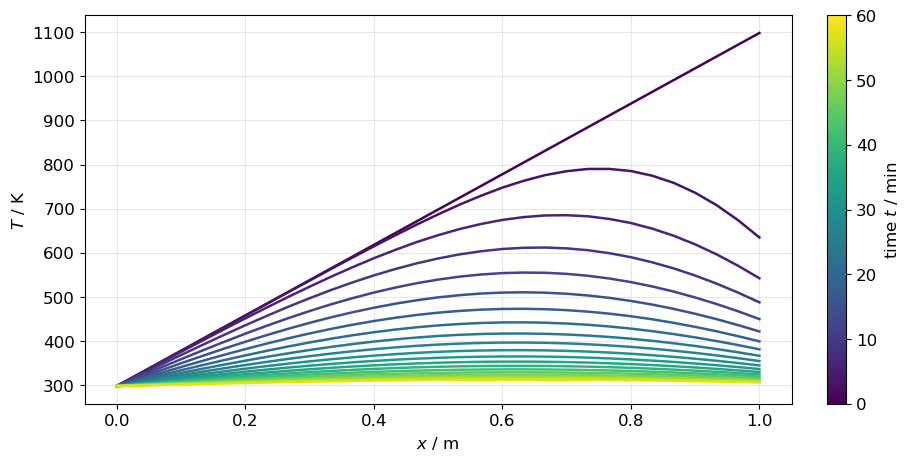

In [6]:
from compeng.ch06_simulation_pde import plot_contours
plot_contours(u_store, t_store, x);

In [7]:
from compeng.ch06_simulation_pde import save_heat_animation
save_heat_animation(u_store, t_store, x, "media/ch06_heat_evolution.gif", interval=200)

PosixPath('media/ch06_heat_evolution.gif')

![Animation of the temperature profile evolving over time](media/ch06_heat_evolution.gif)

### 3.2 Crank-Nicolson method; 1-D heat eqn

The Crank-Nicolson scheme is a semi-implicit method for the 1-D heat equation $\frac{\partial y}{\partial t} = \alpha \frac{\partial^2 y}{\partial x^2}$, averaging the spatial operator between times $n$ and $n+1$:

$$\frac{y_i^{n+1} - y_i^n}{\Delta t} = \frac{\alpha}{2} \left( \frac{y_{i-1}^{n+1} - 2y_i^{n+1} + y_{i+1}^{n+1}}{\Delta x^2} + \frac{y_{i-1}^n - 2y_i^n + y_{i+1}^n}{\Delta x^2} \right).$$

This forms a tridiagonal system $\mathbf{A} \mathbf{y}^{n+1} = \mathbf{b}^n$, unconditionally stable and second-order accurate in time and space.
Adapted code (use scipy.linalg.solve for the system; assumes same parameters/ICs/BCs as FTCS):

In [8]:
# ... (Physical/discretization parameters, IC, BC_1, BC_2 as before)

r = alpha * dt / dx**2  # Diffusion number

# Tridiagonal matrix A (implicit part)
A_diag = np.ones(N+1) * (1 + r)
A_off = np.ones(N) * (-r/2)
A = np.diag(A_diag) + np.diag(A_off, -1) + np.diag(A_off, 1)
A[0, :2] = [1, 0]  # Boundary rows: the solve returns y_0 = b_0 and y_N = b_N
A[-1, -2:] = [0, 1]

In [9]:
y = IC(x)  # Initial condition

u_store = [y.copy()]
t_store = [0]

for t in tspan[1:]:
    # Right-hand side b (explicit part)
    b = y.copy()  # Start with y^n
    b[1:-1] += (r/2) * (y[:-2] - 2*y[1:-1] + y[2:])  # Add explicit diffusion
    b[0] = BC_1(y, t)  # Adjust for BCs
    b[-1] = BC_2(y, t)

    # Solve A y^{n+1} = b
    y = solve(A, b)

    u_store.append(y.copy())
    t_store.append(t)

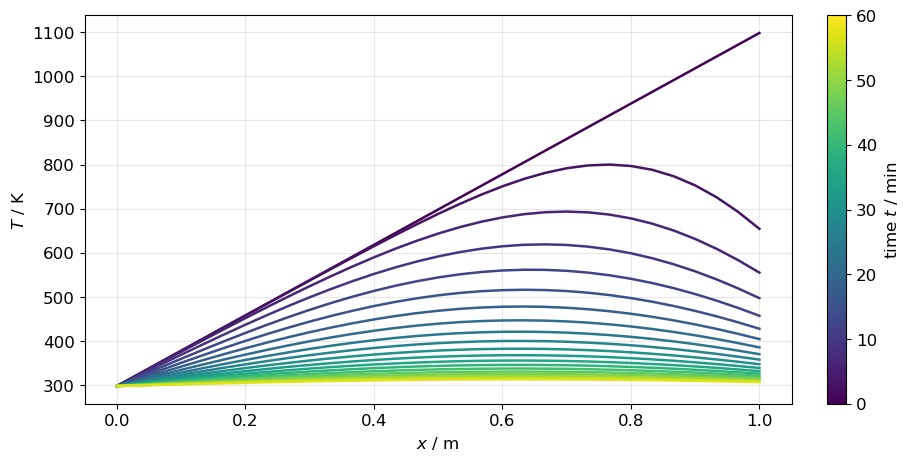

In [10]:
plot_contours(u_store, t_store, x);

## 4. Hyperbolic PDEs (Wave Equation):

Hyperbolic PDEs model wave propagation, where solutions can develop discontinuities or shocks, unlike the smoothing in parabolic systems. The prototypical example is the 1D wave equation:

$$ \frac{\partial^2 y}{\partial t^2} = c^2 \frac{\partial^2 y}{\partial x^2}, $$

where $c$ is the wave speed (e.g., sound speed in propulsion gases).

### 4.1 Solving the 1D Wave Equation via Method of Lines

Using the method of lines (MOL), discretize space with central differences to form a second-order ODE system in time: let $\mathbf{v} = \frac{\partial \mathbf{y}}{\partial t}$, then $\frac{d\mathbf{v}}{dt} = c^2 \mathbf{A} \mathbf{y}$, where $\mathbf{A}$ is the tridiagonal Laplacian matrix from before. Combine into $\frac{d}{dt} \begin{bmatrix} \mathbf{y} \\ \mathbf{v} \end{bmatrix} = \begin{bmatrix} \mathbf{0} & \mathbf{I} \\ c^2 \mathbf{A} & \mathbf{0} \end{bmatrix} \begin{bmatrix} \mathbf{y} \\ \mathbf{v} \end{bmatrix}$.

This is relevant for space applications like acoustic waves in rocket engines or orbital perturbations modeled as wave-like dynamics.

In [11]:
# Parameters
L = 1.0  # Length
N = 50   # Spatial points
dx = L / (N - 1)
x = np.linspace(0, L, N)
c = 1.0  # Wave speed
t_span = (0, 1.0)  # Time interval

# Initial conditions: y0 (displacement), v0 (velocity)
y0 = np.sin(np.pi * x / L)  # Example sine wave, y0[0]=y0[-1]=0
v0 = np.zeros(N)
z0 = np.concatenate([y0, v0])  # Stacked state [y, v]

In [12]:
# ODE function with direct stencil (avoids matrix size issues)
def dydt(t, z): # Wave ODE system
    y, v = z[:N], z[N:]
    dy_dt = v.copy()
    dv_dt = np.zeros_like(v)
    # Interior stencil
    dv_dt[1:-1] = c**2 * (y[:-2] - 2*y[1:-1] + y[2:]) / dx**2
    # Dirichlet BC: fix y[0]=y[-1]=0 by setting dy_dt[0]=dy_dt[-1]=0
    dy_dt[0] = 0
    dy_dt[-1] = 0
    return np.concatenate([dy_dt, dv_dt])

# Solve with solve_ivp
sol = solve_ivp(dydt, t_span, z0, method='RK45', t_eval=np.linspace(*t_span, 100))

# Extract solutions: sol.y[:N, :] for y over time

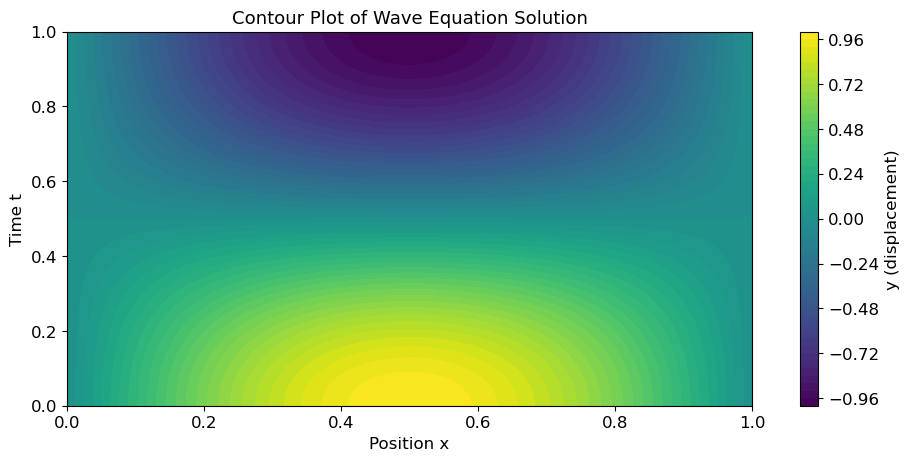

In [13]:
from compeng.ch06_simulation_pde import plot_wave
plot_wave(x, sol.t, sol.y[:N, :]);

### 4.2 Stability Considerations: CFL Condition
The Courant-Friedrichs-Lewy (CFL) condition is a stability criterion for explicit finite difference schemes solving hyperbolic PDEs, like the wave equation. It ensures that the numerical domain of dependence includes the physical one, preventing information from propagating faster than the grid allows. For the 1D wave equation with speed $c$, it requires $\frac{c \Delta t}{\Delta x} \leq 1$ (CFL number $\nu \leq 1$), meaning the time step $\Delta t$ must be small enough so waves don't "skip" grid points.

In practice, violating CFL leads to instability, such as oscillations or divergence. For MOL with explicit integrators (e.g., forward Euler), a similar bound applies due to stiffness from spatial discretization. Implicit methods or adaptive solvers like RK45 in solve_ivp relax this but may still need monitoring for accuracy in high-wavenumber modes.

In space engineering, CFL is crucial for simulating shocks in re-entry flows or acoustic instabilities in propulsion, where fine grids demand tiny steps—often mitigated by implicit schemes or Courant-number-based adaptive time-stepping.

## 5. Further considerations
### 5.1 Higher Dimensions and Computational Cost
While 1D examples illustrate core principles, real engineering PDEs often require 2D/3D extensions. Use scipy.sparse for efficient matrix operations on larger grids to handle increased DOF. Computational cost grows exponentially with dimensions (curse of dimensionality), favoring FEM/FVM over FDM for complex geometries due to better scaling and unstructured mesh flexibility.

### 5.2 Coupled PDE Systems
Coupled PDEs arise when multiple phenomena interact (e.g., thermo-fluid systems). Using MOL, discretize space to yield a DAE-like system (from Chapter 5), solvable with `solve_ivp` or implicit integrators. Index reduction may be needed for high-index DAEs; relate to conservation laws for stability analysis.

## (Optional) 6. Special topic: Fluid dynamics and Navier-Stokes equations
The Navier-Stokes equations govern fluid motion: $\frac{\partial \mathbf{u}}{\partial t} + (\mathbf{u} \cdot \nabla) \mathbf{u} = -\frac{1}{\rho} \nabla p + \nu \nabla^2 \mathbf{u} + \mathbf{f}$, where $\mathbf{u}$ is velocity, $p$ pressure, $\nu$ viscosity.

### 6.1 Overview of Navier-Stokes regimes

The Navier-Stokes equations describe a wide range of fluid flows by balancing inertial, viscous, pressure, and external forces. Flow regimes are primarily classified using dimensionless numbers that highlight dominant physical effects, guiding simplifications in computational models. The Reynolds number, $\text{Re} = \frac{\rho u L}{\mu}$ (where $\rho$ is density, $u$ characteristic velocity, $L$ length scale, and $\mu$ dynamic viscosity), quantifies the ratio of inertial to viscous forces. Regimes are classified by Reynolds number (Re = inertial/viscous forces):

- low Re (laminar, diffusive);
- high Re (turbulent, advective).
- Compressible vs. incompressible based on Mach number.

At low Re ($\text{Re} \ll 1$), viscous forces dominate, resulting in laminar flows with smooth, predictable streamlines and diffusive transport. These are common in microscale or high-viscosity scenarios, such as lubricant films in spacecraft mechanisms or creeping flows in microgravity experiments. Computations simplify to Stokes equations (neglecting inertia), enabling efficient linear solvers but requiring fine grids near boundaries for accurate shear stress predictions.

At high Re ($\text{Re} \gg 1$), inertial forces prevail, leading to turbulent flows with chaotic eddies, enhanced mixing, and increased drag. Examples include atmospheric re-entry (high-speed turbulence) or rocket exhaust plumes. Simulations demand turbulence models (e.g., RANS or LES) as direct resolution is prohibitive; boundary layers thin, necessitating adaptive meshing or wall functions.

Additionally, compressibility is assessed via the Mach number, $\text{Ma} = \frac{u}{a}$ (where $a$ is speed of sound). Incompressible regimes ($\text{Ma} < 0.3$) assume constant density, decoupling pressure via Poisson equations—suitable for low-speed spacecraft attitude control thrusters. Compressible regimes ($\text{Ma} > 0.3$) involve density variations, shocks, and energy equations, as in hypersonic flows during orbital insertion. Hybrid solvers (e.g., pressure-based for low Ma, density-based for high Ma) are used, with shock-capturing schemes to handle discontinuities. In space engineering, regime transitions inform numerical stability and validation against experiments.

### 6.2 Turbulence modeling

Turbulence in fluid flows is characterized by chaotic, irregular motion involving a wide range of eddy sizes and scales, leading to enhanced mixing, drag, and energy dissipation. In engineering contexts like aerospace propulsion or atmospheric re-entry, accurately simulating turbulence is crucial but computationally challenging due to the broad spectrum of scales—from large energy-containing eddies to small dissipative ones. Direct Numerical Simulation (DNS) resolves all scales by solving the full Navier-Stokes equations without modeling, but it requires enormous computational resources (scaling as $\text{Re}^{3}$ or higher, where Re is the Reynolds number), making it impractical for high-Re flows in real-world applications.

To reduce costs, modeling approaches approximate turbulence effects. Reynolds-Averaged Navier-Stokes (RANS) methods decompose variables into mean and fluctuating components (e.g., $\mathbf{u} = \bar{\mathbf{u}} + \mathbf{u}'$), averaging the equations to focus on steady or unsteady means. This introduces Reynolds stresses ($-\rho \overline{\mathbf{u}' \mathbf{u}'}$) that require closure models. A popular example is the k-ε model, which solves transport equations for turbulent kinetic energy $k = \frac{1}{2} \overline{u_i' u_i'}$ and dissipation rate $\varepsilon = \nu \overline{\frac{\partial u_i'}{\partial x_j} \frac{\partial u_i'}{\partial x_j}}$, assuming isotropic eddy viscosity $\nu_t = C_\mu \frac{k^2}{\varepsilon}$. RANS is computationally efficient for steady flows but struggles with unsteady or separated flows, often overpredicting mixing.

Large Eddy Simulation (LES) offers a middle ground by resolving large-scale eddies directly via filtered Navier-Stokes equations, while modeling subgrid-scale (SGS) stresses for small eddies. The filter width (grid size) separates scales, with SGS models like Smagorinsky ($\nu_s = (C_s \Delta)^2 |\bar{S}|$, where $\bar{S}$ is the strain rate) providing closure. LES captures transient dynamics better than RANS, especially in separated flows, but demands finer grids and time steps, increasing cost (though less than DNS). In space engineering, LES is used for rocket plume analysis or turbulent heat transfer.

Hybrid methods like Detached Eddy Simulation (DES) combine RANS near walls (for efficiency) with LES in detached regions. Choice depends on Re, geometry, and resources: RANS for quick design iterations, LES for detailed unsteady predictions. Further reading: Wilcox's Turbulence Modeling for CFD.

### 6.3 Multiphase flows
Involve interfaces (e.g., gas-liquid in propulsion); use VOF for tracking volumes or level-set for sharp interfaces.

### 6.4 Shock capturing methods
For discontinuities in hyperbolic regimes, use upwind schemes or TVD limiters to prevent oscillations while preserving sharpness.

## 7. (Optional) Special Topic: Fluid-Structure Interaction (FSI)
FSI couples fluid flow with structural deformation, e.g., aeroelasticity in spacecraft. Governing equations: Navier-Stokes for fluids, elasticity PDEs for solids ($\nabla \cdot \sigma = \rho \frac{\partial^2 \mathbf{d}}{\partial t^2}$, $\sigma$ stress, $\mathbf{d}$ displacement).

## 8. (Optional) Special topic: Numerical methods for fluid-structure interaction (FSI)

### 8.1 FEM for solid mechanics
Discretize solids with FEM: weak form, basis functions on elements; solve for displacements under loads.

### 8.2 Coupling Fluid and Solid Solvers
Partitioned (sequential) or monolithic (simultaneous) approaches; interpolate interface forces/displacements. Example: Flow-induced vibration of a flexible fin reducing turbulence in von Kármán streets or channels, modeled via iterative coupling for accuracy.

> #### Example: Flow-induced vibration of a flexible fin reducing turbulence in von Kármán streets or channels, modeled via iterative coupling for accuracy.
> Below is a simple Python simulation of a 1D fin (modeled as a cantilever beam) bending under fluid interaction. Use finite differences for the Euler-Bernoulli beam equation $\frac{\partial^2 y}{\partial t^2} + \frac{EI}{\rho A} \frac{\partial^4 y}{\partial x^4} = f(x,t)$, where $f$ is a fluid drag force (e.g., $f = -c_d \frac{\partial y}{\partial t}$, simplified quadratic drag or from potential flow). Couple with a basic fluid model like added mass or viscous damping. Below is a minimal MOL example using SciPy for time integration (assumes uniform beam, fixed at x=0, free at x=L; fluid force as proportional damping for simplicity).

[stub, see later versions of this notebook for full code]

## Further reading

Overview texts:
- Stanley J. Farlow, Partial Differential Equations for Scientists and Engineers, Dover Publications, 1993.
- R.J. LeVeque, Finite Volume Methods for Hyperbolic Problems, Cambridge University Press, 2002.

Seminal papers (turbulence modeling):

- Launder, B.E., & Spalding, D.B. (1974). "The numerical computation of turbulent flows." Computer Methods in Applied Mechanics and Engineering, 3(2), 269–289. This introduces the standard k-ε model, a cornerstone of RANS for industrial simulations, emphasizing closure assumptions and empirical constants.
- Jones, W.P., & Launder, B.E. (1972). "The prediction of laminarization with a two-equation model of turbulence." International Journal of Heat and Mass Transfer, 15(2), 301–314. An early development of low-Re k-ε variants, useful for transitional flows in boundary layers.
- Menter, F.R. (1994). "Two-equation eddy-viscosity turbulence models for engineering applications." AIAA Journal, 32(8), 1598–1605. Proposes the SST k-ω model, blending k-ε and k-ω for better near-wall and free-shear predictions, widely used in aerospace (e.g., airfoil simulations).

For LES, see
- Smagorinsky, J. (1963). "General circulation experiments with the primitive equations: I. The basic experiment." Monthly Weather Review, 91(3), 99–164. This seminal work introduces the Smagorinsky SGS model, foundational for LES in atmospheric and engineering flows.
- Pope, S.B. (2000). Turbulent Flows (Cambridge University Press) for theoretical depth;
- Spalart, P.R. (2009). "Detached-eddy simulation." Annual Review of Fluid Mechanics, 41, 181–202, on hybrid RANS-LES methods for high-Re aerospace applications.


Software libraries:
- FEniCS (FEM for multiphysics)
- PyCFD (CFD simulations).